# Comparing the two Sarasota chlorophyll-a datasets

Issue #14 — Preprocess chlorophyll and wind data from 09/15.

Before merging `ChlorophyllaConcentrationSarasota.csv` (**DS1**) and `ChlorophyllaConcentrationSarasota_Dataset2.csv` (**DS2**), this notebook checks:

1. What columns each file has
2. How the two differ apart from date range:
   1. Grid spacing
   2. Spatial extent
   3. Value levels (sensor bias)
   4. Missing data
   5. Saturated / capped values
   6. Formatting details (units row, coordinate precision)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = "../data"
DS1_PATH = f"{DATA}/ChlorophyllaConcentrationSarasota.csv"
DS2_PATH = f"{DATA}/ChlorophyllaConcentrationSarasota_Dataset2.csv"

## Load the data

Both files are ERDDAP exports. **Row 2 is a units row** rather than data, so we read it separately and skip it when loading.

In [2]:
units1 = pd.read_csv(DS1_PATH, nrows=1)
units2 = pd.read_csv(DS2_PATH, nrows=1)

ds1 = pd.read_csv(DS1_PATH, skiprows=[1])
ds2 = pd.read_csv(DS2_PATH, skiprows=[1])

for df in (ds1, ds2):
    df["time"] = pd.to_datetime(df["time"]).dt.tz_localize(None)

print(f"DS1: {len(ds1):,} rows")
print(f"DS2: {len(ds2):,} rows")

DS1: 4,202,008 rows
DS2: 7,010,094 rows


## 1. Columns in each dataset

In [3]:
print("DS1 columns:", list(ds1.columns))
print("DS2 columns:", list(ds2.columns))
print()
print("Only in DS1:", set(ds1.columns) - set(ds2.columns))
print("Only in DS2:", set(ds2.columns) - set(ds1.columns))

DS1 columns: ['time', 'altitude', 'latitude', 'longitude', 'chlor_a']
DS2 columns: ['time', 'latitude', 'longitude', 'chlor_a']

Only in DS1: {'altitude'}
Only in DS2: set()


In [4]:
ds1.head()

,time,altitude,latitude,longitude,chlor_a
0,2020-06-15 12:00:00,0.0,27.99375,276.50625,NaN
1,2020-06-15 12:00:00,0.0,27.99375,276.54375,NaN
2,2020-06-15 12:00:00,0.0,27.99375,276.58125,NaN
3,2020-06-15 12:00:00,0.0,27.99375,276.61875,NaN
4,2020-06-15 12:00:00,0.0,27.99375,276.65625,NaN


In [5]:
ds2.head()

,time,latitude,longitude,chlor_a
0,2010-01-01 12:00:00,28.020832,276.47920,NaN
1,2010-01-01 12:00:00,28.020832,276.52084,NaN
2,2010-01-01 12:00:00,28.020832,276.56250,NaN
3,2010-01-01 12:00:00,28.020832,276.60420,NaN
4,2010-01-01 12:00:00,28.020832,276.64584,NaN


In [6]:
cols = sorted(set(ds1.columns) | set(ds2.columns), key=lambda c: list(ds1.columns).index(c) if c in ds1 else 99)
pd.DataFrame({
    "in DS1": [c in ds1.columns for c in cols],
    "DS1 dtype": [str(ds1[c].dtype) if c in ds1 else "-" for c in cols],
    "in DS2": [c in ds2.columns for c in cols],
    "DS2 dtype": [str(ds2[c].dtype) if c in ds2 else "-" for c in cols],
}, index=cols)

,in DS1,DS1 dtype,in DS2,DS2 dtype
time,True,datetime64[us],True,datetime64[us]
altitude,True,float64,False,-
latitude,True,float64,True,float64
longitude,True,float64,True,float64
chlor_a,True,float64,True,float64


`altitude` exists only in DS1. Check whether it carries any information:

In [7]:
ds1["altitude"].value_counts(dropna=False)

altitude
0.0    4202008
Name: count, dtype: int64

It is always 0.0, so it can be dropped. After that, both datasets share `time, latitude, longitude, chlor_a`.

### Date ranges (for reference)

In [8]:
pd.DataFrame({
    "start": [ds1.time.min(), ds2.time.min()],
    "end": [ds1.time.max(), ds2.time.max()],
    "unique days": [ds1.time.nunique(), ds2.time.nunique()],
}, index=["DS1", "DS2"])

,start,end,unique days
DS1,2020-06-15 12:00:00,2026-09-05 12:00:00,2228
DS2,2010-01-01 12:00:00,2022-05-31 12:00:00,4511


---
# 2. Differences apart from date range

### 2.1 Grid spacing
Measure the step between neighbouring latitude and longitude values.

In [9]:
def grid_info(df):
    lats = np.sort(df.latitude.unique())
    lons = np.sort(df.longitude.unique())
    return {
        "lat step (deg)": np.median(np.diff(lats)).round(5),
        "lon step (deg)": np.median(np.diff(lons)).round(5),
        "approx km": round(np.median(np.diff(lats)) * 111, 2),
        "n lat": len(lats), "n lon": len(lons),
        "grid cells": len(lats) * len(lons),
    }

pd.DataFrame({"DS1": grid_info(ds1), "DS2": grid_info(ds2)})

,DS1,DS2
lat step (deg),0.0375,0.04167
lon step (deg),0.0375,0.04166
approx km,4.1600,4.62000
n lat,41.0000,37.00000
n lon,46.0000,42.00000
grid cells,1886.0000,1554.00000


How many grid points are exactly shared by both datasets?

In [10]:
pts1 = set(zip(ds1.latitude.round(4), ds1.longitude.round(4)))
pts2 = set(zip(ds2.latitude.round(4), ds2.longitude.round(4)))
print(f"DS1 points: {len(pts1)}, DS2 points: {len(pts2)}, exactly shared: {len(pts1 & pts2)}")

DS1 points: 1886, DS2 points: 1554, exactly shared: 0


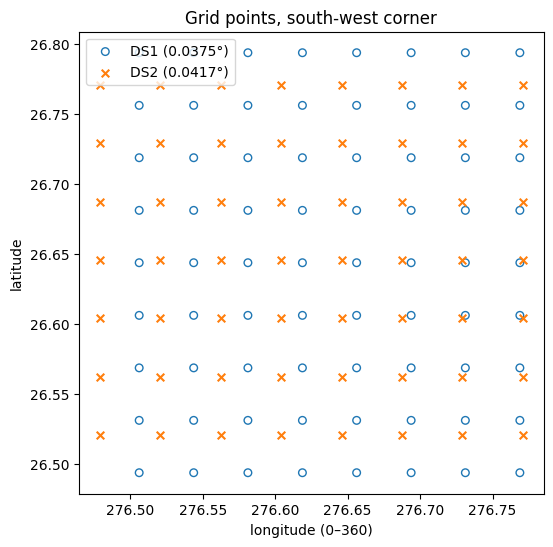

In [11]:
# Zoom in on one corner to see that the grids do not line up
g1 = pd.DataFrame(list(pts1), columns=["lat", "lon"])
g2 = pd.DataFrame(list(pts2), columns=["lat", "lon"])
box = lambda g: g[(g.lat < 26.8) & (g.lon < 276.8)]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(box(g1).lon, box(g1).lat, s=30, marker="o", facecolors="none", edgecolors="tab:blue", label="DS1 (0.0375°)")
ax.scatter(box(g2).lon, box(g2).lat, s=30, marker="x", color="tab:orange", label="DS2 (0.0417°)")
ax.set_xlabel("longitude (0–360)"); ax.set_ylabel("latitude")
ax.set_title("Grid points, south-west corner")
ax.legend(); plt.show()

**Takeaway:** both datasets use evenly spaced grids, but with different spacing (DS1 0.0375°, DS2 0.0417°), and **no grid point appears in both**. A direct merge on `latitude, longitude` would therefore return nothing. Before merging, each DS2 point must be matched to its **nearest DS1 point by distance**. Rounding coordinates to DS1's spacing does not work, because DS1's points sit exactly halfway between multiples of 0.0375 and neighbouring cells collide (see 2.3). Alternatively, both could be averaged onto a common coarser grid (e.g. 0.1°), at the cost of detail.

### 2.2 Spatial extent

In [12]:
ext = pd.DataFrame({
    name: {"lat min": df.latitude.min(), "lat max": df.latitude.max(),
           "lon min": df.longitude.min(), "lon max": df.longitude.max(),
           "lon min (-180..180)": df.longitude.min() - 360, "lon max (-180..180)": df.longitude.max() - 360}
    for name, df in [("DS1", ds1), ("DS2", ds2)]
})
ext.round(4)

,DS1,DS2
lat min,26.4938,26.5208
lat max,27.9938,28.0208
lon min,276.5062,276.4792
lon max,278.1938,278.1875
lon min (-180..180),-83.4937,-83.5208
lon max (-180..180),-81.8062,-81.8125


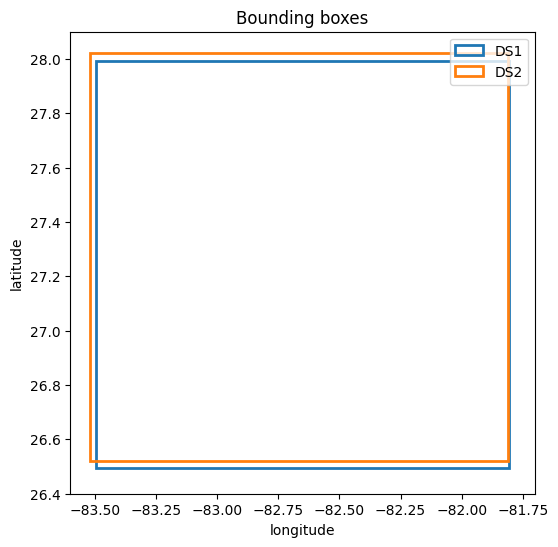

In [13]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(6, 6))
for name, df, c in [("DS1", ds1, "tab:blue"), ("DS2", ds2, "tab:orange")]:
    x0, x1 = df.longitude.min() - 360, df.longitude.max() - 360
    y0, y1 = df.latitude.min(), df.latitude.max()
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=2, ec=c, label=name))
ax.set_xlim(-83.6, -81.7); ax.set_ylim(26.4, 28.1)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Bounding boxes"); ax.legend(); plt.show()

**Takeaway:** both datasets cover the same requested box (lat 26.5–28, lon −83.5 to −81.8). The outermost pixel centres differ by up to ~0.03° (~3 km) only because each grid fills that box with its own spacing, so the two differ only in thin edge strips about one pixel wide. Edge pixels without a nearby partner simply get no match. Longitude is stored as 0–360 (276.5 = −83.5); habsos, florida_cyanotoxins, MoteMarine_BottomTemp and CHIRPS precipitation use −180..180, so subtract 360 before any spatial join. SarasotaWindData is also 0–360 and needs the same conversion.

### 2.3 Value levels (sensor bias)
Compare the two datasets where they overlap in time (2020-06-15 → 2022-05-31): pair each DS2 pixel with the DS1 pixel at the same place, on the same day.

**Why not just round coordinates?** DS1's grid points sit exactly halfway between multiples of 0.0375, so rounding sends neighbouring cells to the same index:

In [14]:
G = 0.0375
lats = np.sort(ds1.latitude.unique())[:6]
pd.DataFrame({"DS1 latitude": lats, "latitude / 0.0375": lats / G, "rounded": (lats / G).round().astype(int)})

,DS1 latitude,latitude / 0.0375,rounded
0,26.49375,706.5,706
1,26.53125,707.5,708
2,26.56875,708.5,708
3,26.60625,709.5,710
4,26.64375,710.5,710
5,26.68125,711.5,712


Rows 1 and 2 both become 708, and rows 3 and 4 both become 710: two different cells get the same label. Instead, each DS2 pixel is matched to its **nearest DS1 pixel by distance**, keeping only matches within 2.5 km:

In [15]:
from scipy.spatial import cKDTree

lo, hi = pd.Timestamp("2020-06-15"), pd.Timestamp("2022-05-31")

def to_km(lat, lon):
    # degrees -> km (longitude degrees are shorter at Sarasota's latitude)
    return np.c_[np.asarray(lat) * 111, np.asarray(lon) * 111 * np.cos(np.radians(27.3))]

g1 = ds1[["latitude", "longitude"]].drop_duplicates().reset_index(drop=True)
g2 = ds2[["latitude", "longitude"]].drop_duplicates().reset_index(drop=True)
dist, idx = cKDTree(to_km(g1.latitude, g1.longitude)).query(to_km(g2.latitude, g2.longitude))
lookup = g2.assign(lat_ds1=g1.latitude.values[idx], lon_ds1=g1.longitude.values[idx], dist_km=dist)
lookup = lookup[lookup.dist_km <= 2.5]

def overlap(df):
    d = df.dropna(subset=["chlor_a"]).copy()
    d["date"] = d.time.dt.normalize()
    d = d[d.date.between(lo, hi)]
    return d[(d.chlor_a >= 0.01) & (d.chlor_a < 99)]   # leave out the limit values (2.5)

d2 = overlap(ds2).merge(lookup, on=["latitude", "longitude"])
pairs = overlap(ds1).merge(
    d2[["date", "lat_ds1", "lon_ds1", "chlor_a"]],
    left_on=["date", "latitude", "longitude"], right_on=["date", "lat_ds1", "lon_ds1"],
    suffixes=("_ds1", "_ds2"),
)
log1, log2 = np.log10(pairs.chlor_a_ds1), np.log10(pairs.chlor_a_ds2)

print(f"Matched pixel-days: {len(pairs):,}  (duplicates: {pairs.duplicated(['date', 'latitude', 'longitude']).sum()})")
print(f"Typical match distance: {lookup.dist_km.median():.1f} km")
print(f"Correlation (log10): {np.corrcoef(log1, log2)[0, 1]:.2f}")
print(f"Median ratio DS1/DS2: {10 ** np.median(log1 - log2):.2f}  -> DS1 reads ~{(1 - 10 ** np.median(log1 - log2)) * 100:.0f}% lower")

Matched pixel-days: 110,262  (duplicates: 0)
Typical match distance: 1.6 km
Correlation (log10): 0.96
Median ratio DS1/DS2: 0.92  -> DS1 reads ~8% lower


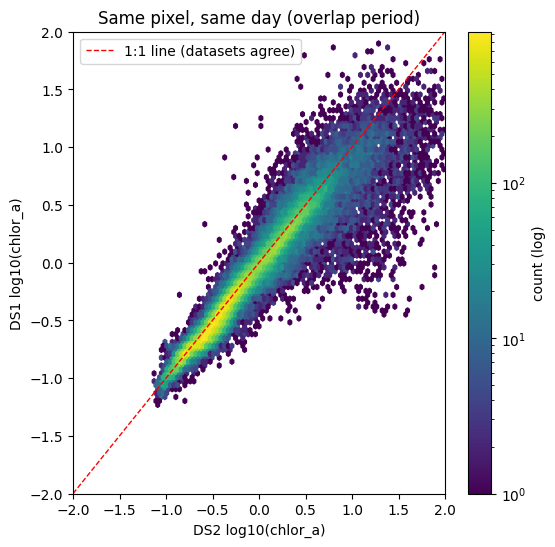

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
hb = ax.hexbin(log2, log1, gridsize=80, bins="log", cmap="viridis")
lim = [-2, 2]
ax.plot(lim, lim, "r--", lw=1, label="1:1 line (datasets agree)")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("DS2 log10(chlor_a)"); ax.set_ylabel("DS1 log10(chlor_a)")
ax.set_title("Same pixel, same day (overlap period)")
fig.colorbar(hb, label="count (log)"); ax.legend(); plt.show()

**Is the gap the same everywhere?** The chart below shows how much lower DS1 reads than DS2, split by how green the water is (left) and by season (right). 0 means the two datasets agree.

*Chlorophyll level uses the average of both datasets, so neither one decides which group a pair falls into.*

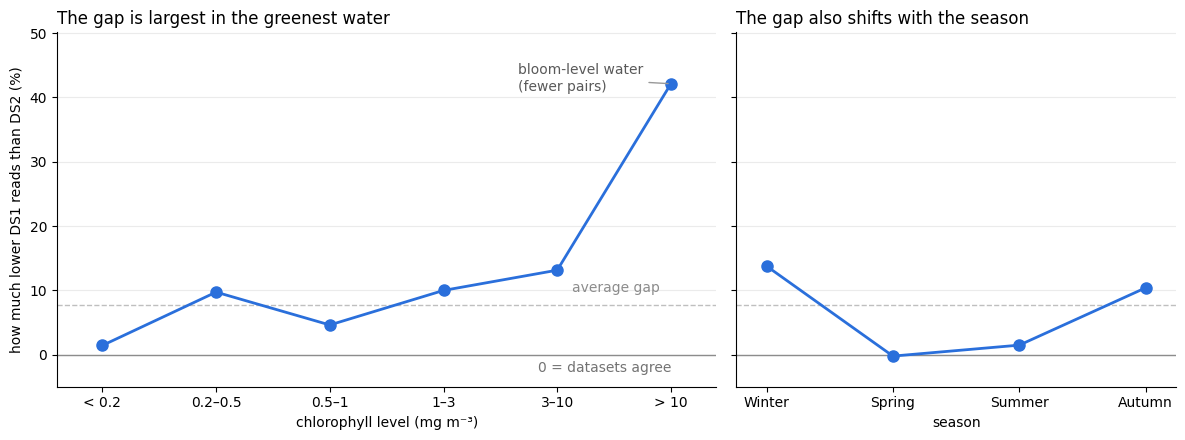

In [17]:
pairs["gap_log"] = log1 - log2
pairs["level"] = pd.cut(np.sqrt(pairs.chlor_a_ds1 * pairs.chlor_a_ds2),
                        [0, 0.2, 0.5, 1, 3, 10, 100],
                        labels=["< 0.2", "0.2–0.5", "0.5–1", "1–3", "3–10", "> 10"])
season_of = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
             6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
pairs["season"] = pd.Categorical(pairs.date.dt.month.map(season_of),
                                 ["Winter", "Spring", "Summer", "Autumn"], ordered=True)

pct_lower = lambda g: (1 - 10 ** g.median()) * 100
by_level = pairs.groupby("level", observed=True).gap_log.agg(pct_lower)
by_season = pairs.groupby("season", observed=True).gap_log.agg(pct_lower)
overall = pct_lower(pairs.gap_log)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
for ax, series, xlabel, title in [
    (axes[0], by_level, "chlorophyll level (mg m⁻³)", "The gap is largest in the greenest water"),
    (axes[1], by_season, "season", "The gap also shifts with the season"),
]:
    x = range(len(series))
    ax.axhline(0, color="0.55", lw=1)
    ax.axhline(overall, color="0.75", lw=1, ls="--")
    ax.plot(x, series.values, "-o", color="#2a6fdb", lw=2, ms=8)
    ax.set_xticks(list(x), series.index.astype(str))
    ax.set_xlabel(xlabel); ax.set_title(title, loc="left")
    ax.grid(axis="y", color="0.92"); ax.spines[["top", "right"]].set_visible(False)
    ax.margins(x=0.08)

axes[0].set_ylabel("how much lower DS1 reads than DS2 (%)")
axes[0].text(len(by_level) - 1, -1, "0 = datasets agree", color="0.45", va="top", ha="right")
axes[0].text(len(by_level) - 1.1, overall + 1.5, "average gap", color="0.55", va="bottom", ha="right")
axes[0].annotate("bloom-level water\n(fewer pairs)", (len(by_level) - 1, by_level.iloc[-1]),
                 xytext=(-110, -5), textcoords="offset points", color="0.35",
                 arrowprops=dict(arrowstyle="-", color="0.6"))
axes[0].set_ylim(-5, max(by_level.max(), by_season.max()) + 8)
plt.tight_layout(); plt.show()

**Takeaway:** at the same place and day the two datasets track each other closely, but DS1 reads lower than DS2, about 8% on average.

**The gap depends on the water.** It is small in clear water, close to the average in typical water, and much larger at bloom levels (left chart). It also shifts with the season (right chart).

→ A single correction factor would fix typical water but leave pre-2020 blooms too high. Adjust DS2 **level by level** before stacking, e.g. with quantile mapping (*look up:* "quantile mapping", "CDF matching satellite").

**Don't compare daily area-wide medians instead.** Clouds hide different pixels in each dataset on a given day, so the medians describe different water and give a misleading answer:

In [18]:
m1 = ds1[ds1.time.between(lo, hi)].groupby(ds1.time.dt.normalize()).chlor_a.median()
m2 = ds2[ds2.time.between(lo, hi)].groupby(ds2.time.dt.normalize()).chlor_a.median()
daily = pd.concat([m1.rename("ds1"), m2.rename("ds2")], axis=1, sort=True).dropna()
print(f"Daily-median correlation: {daily.corr().iloc[0, 1]:.2f}  (vs {np.corrcoef(log1, log2)[0, 1]:.2f} for matched pixels)")
print(f"Daily-median ratio DS1/DS2: {(daily.ds1 / daily.ds2).median():.2f}  (wrong direction: different pixels are being compared)")

Daily-median correlation: 0.12  (vs 0.96 for matched pixels)
Daily-median ratio DS1/DS2: 1.14  (wrong direction: different pixels are being compared)


### 2.4 Missing data

In [19]:
def missing_info(df):
    per_cell = df.groupby(["latitude", "longitude"]).chlor_a.apply(lambda s: s.notna().mean())
    return {
        "% NaN overall": round(df.chlor_a.isna().mean() * 100, 1),
        "grid cells": len(per_cell),
        "cells never valid": int((per_cell == 0).sum()),
        "cells >20% valid": int((per_cell > 0.2).sum()),
        "days with no valid pixel": int(df.groupby("time").chlor_a.count().eq(0).sum()),
    }

pd.DataFrame({"DS1": missing_info(ds1), "DS2": missing_info(ds2)})

,DS1,DS2
% NaN overall,75.3,80.8
grid cells,1886.0,1554.0
cells never valid,558.0,565.0
cells >20% valid,1197.0,849.0
days with no valid pixel,391.0,1585.0


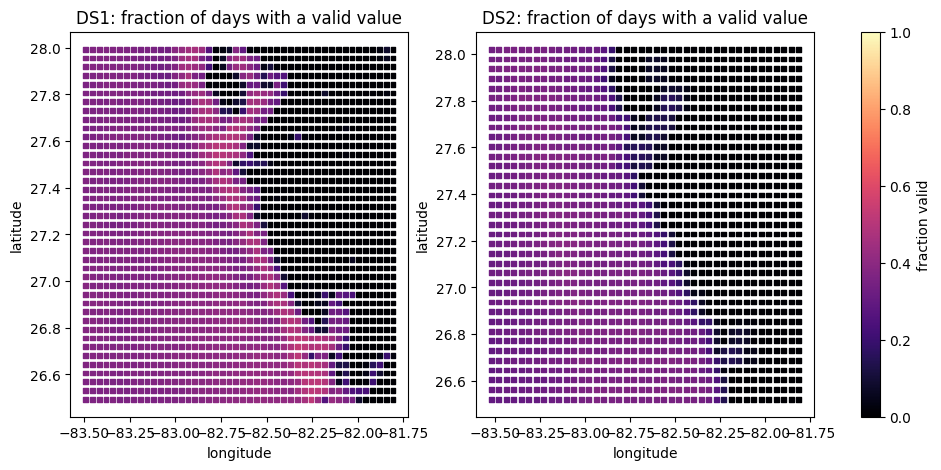

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, df) in zip(axes, [("DS1", ds1), ("DS2", ds2)]):
    frac = df.groupby(["latitude", "longitude"]).chlor_a.apply(lambda s: s.notna().mean()).reset_index()
    sc = ax.scatter(frac.longitude - 360, frac.latitude, c=frac.chlor_a, s=12, marker="s", cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"{name}: fraction of days with a valid value")
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
fig.colorbar(sc, ax=axes, label="fraction valid"); plt.show()

#### Where do the NaNs come from?

Three checks: (1) are never-valid cells really land, (2) how the NaNs split between land and water, (3) how coverage changes with distance from the coast and by month.

The land check uses the `global-land-mask` package (1 km GLOBE land/water map). Install it once with `pip install global-land-mask`.

In [21]:
from global_land_mask import globe

def cell_stats(df):
    c = df.groupby(["latitude", "longitude"]).chlor_a.agg(frac=lambda s: s.notna().mean()).reset_index()
    c["lon"] = c.longitude - 360
    c["centre_on_land"] = globe.is_land(c.latitude.values, c.lon.values)
    # share of land inside each cell, sampled on a 5x5 grid of points within the cell
    step = np.median(np.diff(np.sort(c.latitude.unique())))
    off = np.linspace(-0.45 * step, 0.45 * step, 5)
    c["land_share"] = np.mean([globe.is_land(c.latitude.values + a, c.lon.values + b) for a in off for b in off], axis=0)
    # distance (km) from each cell to the nearest never-valid (land) cell
    km = lambda d: np.c_[d.latitude * 111, d.lon * 111 * np.cos(np.radians(27.3))]
    from scipy.spatial import cKDTree
    tree = cKDTree(km(c[c.frac == 0]))
    c["km_to_land"] = tree.query(km(c))[0]
    return c

cells = {"DS1": cell_stats(ds1), "DS2": cell_stats(ds2)}

rows = {}
for name, df in [("DS1", ds1), ("DS2", ds2)]:
    c = cells[name]
    never = c[c.frac == 0]
    pct_nan = df.chlor_a.isna().mean() * 100
    pct_never = len(never) / len(c) * 100          # every cell has the same number of rows
    rows[name] = {
        "% of rows NaN": round(pct_nan, 1),
        "never-valid cells": len(never),
        "never-valid: centre on land (%)": round(never.centre_on_land.mean() * 100),
        "never-valid: entirely water (%)": round((never.land_share == 0).mean() * 100),
        "NaN rows from never-valid cells (% of rows)": round(pct_never, 1),
        "NaN rows from water cells (% of rows)": round(pct_nan - pct_never, 1),
        "share of NaNs that are land cells (%)": round(pct_never / pct_nan * 100),
    }
pd.DataFrame(rows)

,DS1,DS2
% of rows NaN,75.3,80.8
never-valid cells,558.0,565.0
never-valid: centre on land (%),100.0,97.0
never-valid: entirely water (%),0.0,0.0
NaN rows from never-valid cells (% of rows),29.6,36.4
NaN rows from water cells (% of rows),45.7,44.4
share of NaNs that are land cells (%),39.0,45.0


In [ ]:
bands = [0, 10, 25, 50, 200]
labels = ["< 10 km", "10–25 km", "25–50 km", "> 50 km"]
pd.DataFrame({
    name: c[c.frac > 0].groupby(pd.cut(c[c.frac > 0].km_to_land, bands, labels=labels), observed=True).frac.mean().round(2)
    for name, c in cells.items()
}).rename_axis("distance from land").T.assign(note="fraction of days with a valid value")

distance from land,< 10 km,10–25 km,25–50 km,> 50 km,note
DS1,0.19,0.42,0.38,0.38,fraction of days with a valid value
DS2,0.11,0.30,0.35,0.34,fraction of days with a valid value


In [23]:
by_month = {}
for name, df in [("DS1", ds1), ("DS2", ds2)]:
    c = cells[name]
    water = df.merge(c[c.frac > 0][["latitude", "longitude"]], on=["latitude", "longitude"])
    by_month[name] = (water.chlor_a.isna().groupby(water.time.dt.month).mean() * 100).round()
pd.DataFrame(by_month).T.rename_axis(columns="month").assign(note="% of water-cell days missing")

month,1,2,3,4,5,6,7,8,9,10,11,12,note
DS1,64.0,50.0,53.0,63.0,65.0,73.0,78.0,75.0,73.0,61.0,58.0,61.0,% of water-cell days missing
DS2,71.0,64.0,61.0,69.0,68.0,79.0,82.0,78.0,73.0,62.0,62.0,69.0,% of water-cell days missing


**Takeaway:** a NaN means the pixel was removed by the product's quality masks. If a pixel is flagged for land, cloud, stray light, sun glint or failed atmospheric correction, *"the pixel is not used in the Level-3 composite"* [1]. When no usable pixel is left for a grid cell that day, the value is stored as NaN.

- **Never-valid cells (black) are land.** Checked against a 1 km land mask [2], every never-valid cell contains land (DS1 100%, DS2 97% centred on land; none are pure water). They account for ~30–36% of all rows (39–45% of the NaNs) → **drop them**.
  *Look up:* "land mask", "GLOBE 1 km dataset", "ocean color LAND flag"

- **Coastline cells are only sometimes valid.** Cells within ~10 km of land have data on ~11–19% of days vs ~35–40% offshore (table above). A ~4 km cell on the coast mixes land and water, and light from bright land contaminates nearby water pixels [3] → **keep, but flag as coastal**.
  *Look up:* "mixed pixel remote sensing", "adjacency effect ocean color"

- **Water cells are still missing on ~65–70% of days.** This is the majority of NaNs (~44–46% of rows). Causes are clouds, the stray-light mask placed around cloud edges, and sun glint; the loss *"must be due to factors other than clouds"* alone [1]. The gaps peak in June–September, Florida's rainy season [4].
  *Look up:* "ocean color stray light mask", "sun glint satellite ocean", "Level-2 flags l2_flags", "Florida rainy season"

- **Don't fill these gaps with a single mean/median.** It would make cloudy days look like average days and erase bloom signals, and quality masks can remove dense-bloom pixels more often than clear water [5] → **use backward-looking space/time windows plus a "missing" flag**.
  *Look up:* "missing not at random (MNAR)" [6], "temporal compositing ocean color", "data leakage time series" [7]

**Sources**

1. Hu, C., Barnes, B., Feng, L., Wang, M. & Jiang, L. *On the interplay between ocean color data quality and data quantity: Impacts of quality control flags.* University of South Florida / NOAA NESDIS. [NOAA Repository PDF](https://repository.library.noaa.gov/view/noaa/47133/noaa_47133_DS1.pdf) — see Table 1 (flag list) and Section 2.
2. Karin, T. *global-land-mask* (Python package; GLOBE dataset, 1 km). [GitHub](https://github.com/toddkarin/global-land-mask)
3. Bulgarelli, B. & Zibordi, G. (2018). On the detectability of adjacency effects in ocean color remote sensing of mid-latitude coastal environments by SeaWiFS, MODIS-A, MERIS, OLCI, OLI and MSI. *Remote Sensing of Environment.* [PMC](https://pmc.ncbi.nlm.nih.gov/articles/PMC5890359/)
4. National Weather Service Tampa Bay. *Rainy Season.* [Link](https://www.weather.gov/tbw/rainyseason)
5. Houskeeper, H. F. & Kudela, R. M. *Behind the masks in coastal ocean color.* Ocean Optics Conference (study area: Monterey Bay, CA). [PDF](https://oceanopticsconference.org/extended/Houskeeper_Henry.pdf)
6. Wikipedia. *Missing data* (section on missing not at random). [Link](https://en.wikipedia.org/wiki/Missing_data)
7. Wikipedia. *Leakage (machine learning).* [Link](https://en.wikipedia.org/wiki/Leakage_(machine_learning))

### 2.5 Saturated / capped values

In [24]:
pd.DataFrame({
    "DS1": ds1.chlor_a.describe(percentiles=[.5, .99, .999]),
    "DS2": ds2.chlor_a.describe(percentiles=[.5, .99, .999]),
}).round(3)

,DS1,DS2
count,1039512.000,1346118.000
mean,2.278,1.231
std,4.971,3.514
min,0.001,0.061
50%,0.568,0.432
99%,22.339,15.267
99.9%,59.129,49.860
max,100.000,99.906


In [25]:
print("DS1 values >= 99:", (ds1.chlor_a >= 99).sum())
print("DS2 values >= 99:", (ds2.chlor_a >= 99).sum())
print()
print("Top DS1 values:", ds1.chlor_a.nlargest(5).round(3).tolist())
print("Top DS2 values:", ds2.chlor_a.nlargest(5).round(3).tolist())

DS1 values >= 99: 10
DS2 values >= 99: 10

Top DS1 values: [100.0, 99.779, 99.621, 99.581, 99.568]


Top DS2 values: [99.906, 99.906, 99.906, 99.906, 99.531]


Now the **low end**. NASA/NOAA chlorophyll products have a valid range of 0.001–100 mg m⁻³, so check for values sitting at the bottom limit too:

In [26]:
print("DS1 values < 0.01:", (ds1.chlor_a < 0.01).sum(), "| exactly 0.001:", (ds1.chlor_a.round(4) == 0.001).sum())
print("DS2 values < 0.01:", (ds2.chlor_a < 0.01).sum(), "| exactly 0.001:", (ds2.chlor_a.round(4) == 0.001).sum())
print()
print("Smallest DS1 values:", ds1.chlor_a.nsmallest(5).round(4).tolist())
print("Smallest DS2 values:", ds2.chlor_a.nsmallest(5).round(4).tolist())

DS1 values < 0.01: 20 | exactly 0.001: 7
DS2 values < 0.01: 0 | exactly 0.001: 0



Smallest DS1 values: [0.001, 0.001, 0.001, 0.001, 0.001]


Smallest DS2 values: [0.0615, 0.0615, 0.0615, 0.0621, 0.0621]


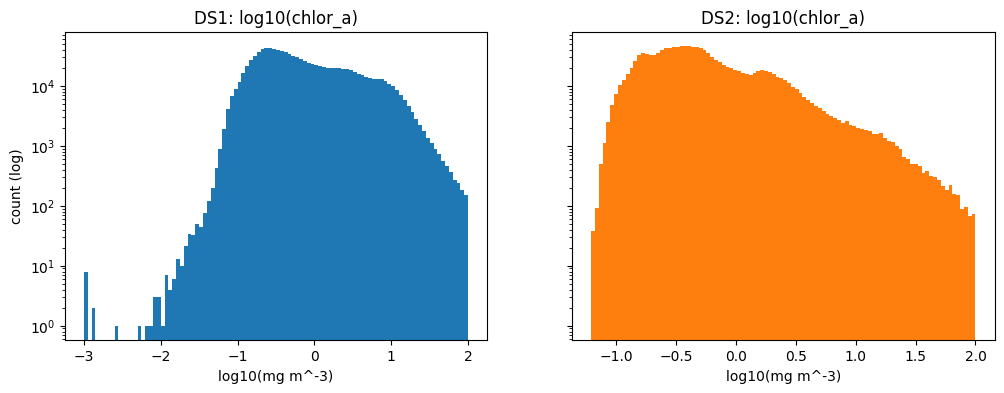

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, df) in zip(axes, [("DS1", ds1), ("DS2", ds2)]):
    ax.hist(np.log10(df.chlor_a.dropna()), bins=100, color="tab:blue" if name == "DS1" else "tab:orange")
    ax.set_title(f"{name}: log10(chlor_a)"); ax.set_xlabel("log10(mg m^-3)"); ax.set_yscale("log")
axes[0].set_ylabel("count (log)"); plt.show()

### Mean vs median: raw vs log

In skewed data the **mean** gets pulled toward the few very high values, while the **median** (the middle value) stays with the typical pixel. Compare them on the raw scale and after `log10`:

In [28]:
rows = {}
for name, df in [("DS1", ds1), ("DS2", ds2)]:
    c = df.chlor_a.dropna()
    c = c[c >= 0.01]                      # exclude the DS1 low-end values flagged below
    lc = np.log10(c)
    rows[name] = {
        "raw median (mg m⁻³)": c.median(),
        "raw mean (mg m⁻³)": c.mean(),
        "raw mean / median": c.mean() / c.median(),
        "log10 median": lc.median(),
        "log10 mean": lc.mean(),
        "log10 mean, back in mg m⁻³": 10 ** lc.mean(),
    }
pd.DataFrame(rows).round(3)

,DS1,DS2
raw median (mg m⁻³),0.568,0.432
raw mean (mg m⁻³),2.278,1.231
raw mean / median,4.012,2.848
log10 median,-0.246,-0.364
log10 mean,-0.114,-0.273
"log10 mean, back in mg m⁻³",0.769,0.533


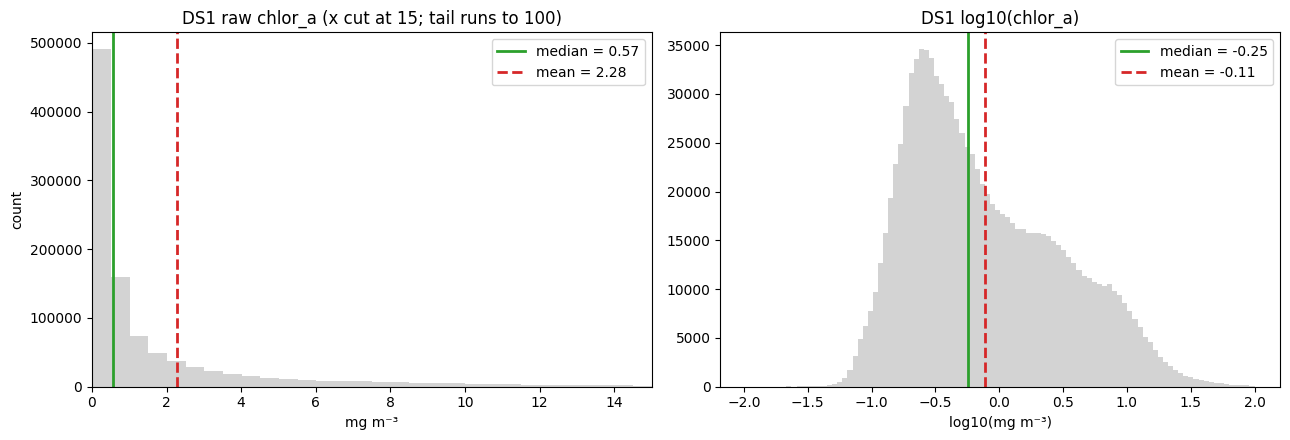

In [29]:
c = ds1.chlor_a.dropna()
c = c[c >= 0.01]
lc = np.log10(c)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.hist(c, bins=200, color="lightgray")
ax.axvline(c.median(), color="tab:green", lw=2, label=f"median = {c.median():.2f}")
ax.axvline(c.mean(), color="tab:red", lw=2, ls="--", label=f"mean = {c.mean():.2f}")
ax.set_xlim(0, 15)
ax.set_title("DS1 raw chlor_a (x cut at 15; tail runs to 100)")
ax.set_xlabel("mg m⁻³"); ax.set_ylabel("count"); ax.legend()

ax = axes[1]
ax.hist(lc, bins=100, color="lightgray")
ax.axvline(lc.median(), color="tab:green", lw=2, label=f"median = {lc.median():.2f}")
ax.axvline(lc.mean(), color="tab:red", lw=2, ls="--", label=f"mean = {lc.mean():.2f}")
ax.set_title("DS1 log10(chlor_a)")
ax.set_xlabel("log10(mg m⁻³)"); ax.legend()

plt.tight_layout(); plt.show()

**Why this matters — why we use log10**

**1. On the raw scale, the mean misrepresents the typical pixel.** Most pixels are clear water (median ≈ 0.4–0.6 mg m⁻³), but a small number of very high values pull the mean up to roughly 3–4× the median. The mean ends up describing water that is greener than most pixels actually are. Anything built on the mean and standard deviation — `StandardScaler`, correlations, linear models — inherits that distortion: the few high values dominate, and the ordinary range of variation is squeezed into a tiny band.

**2. On the log scale, mean and median nearly agree.** After `log10`, each step means "×10", so a pixel going 0.5 → 5 counts the same as 5 → 50. The high values no longer pull the centre, the mean sits next to the median, and the spread is even across the range. This is how chlorophyll behaves physically (it grows and shrinks by multiples), it is how the satellite algorithm is fit [1], and it is why ocean chlorophyll is described as log-normal [4].

**In practice:** use `log_chl = log10(chlor_a)` for scaling, correlations and as the model feature; report typical values with the median (or the log mean converted back to mg m⁻³, which lands close to the median); keep raw `chlor_a` only for thresholds in real units.

### Why not IQR or winsorizing?

What the IQR rule (1.5 × IQR above Q3) and winsorizing (cap at the 99th percentile) would actually do to the chlorophyll data:

In [30]:
rows = {}
for name, df in [("DS1", ds1), ("DS2", ds2)]:
    c = df.chlor_a.dropna()
    c = c[c >= 0.01]
    q1, q3 = c.quantile([0.25, 0.75])
    fence = q3 + 1.5 * (q3 - q1)
    p99 = c.quantile(0.99)
    lc = np.log10(c)
    lq1, lq3 = lc.quantile([0.25, 0.75])
    log_fence = lq3 + 1.5 * (lq3 - lq1)
    rows[name] = {
        "Q1 (mg m⁻³)": round(q1, 2),
        "Q3 (mg m⁻³)": round(q3, 2),
        "IQR upper fence (mg m⁻³)": round(fence, 2),
        "pixels flagged by IQR": f"{(c > fence).sum():,} ({(c > fence).mean():.1%})",
        "pixels ≥ 10 mg m⁻³": f"{(c >= 10).sum():,}",
        "of those, flagged by IQR": f"{(c[c >= 10] > fence).mean():.0%}",
        "winsorize 99th pct cut-off (mg m⁻³)": round(p99, 1),
        "pixels flattened by winsorizing": f"{(c > p99).sum():,}",
        "IQR fence on log scale (mg m⁻³)": round(10 ** log_fence, 1),
        "pixels flagged on log scale": f"{(lc > log_fence).mean():.2%}",
    }
pd.DataFrame(rows)

,DS1,DS2
Q1 (mg m⁻³),0.26,0.25
Q3 (mg m⁻³),2.07,0.96
IQR upper fence (mg m⁻³),4.8,2.03
pixels flagged by IQR,"133,503 (12.8%)","164,104 (12.2%)"
pixels ≥ 10 mg m⁻³,"52,360","23,680"
"of those, flagged by IQR",100%,100%
winsorize 99th pct cut-off (mg m⁻³),22.3,15.3
pixels flattened by winsorizing,"10,394","13,460"
IQR fence on log scale (mg m⁻³),47.8,7.3
pixels flagged on log scale,0.18%,2.52%


**What this means**

- **The IQR rule would delete about 1 in 8 valid pixels, including every pixel at 10 mg m⁻³ or above.** Because half of all values are below ~0.5, Q1 and Q3 sit very low, so the fence lands at only ~2–5 mg m⁻³. Ordinary greener coastal water gets flagged together with the blooms.
- **Winsorizing would flatten every value above ~15–22 mg m⁻³ into the same number.** A moderate bloom and an intense one would look identical to the model — exactly where the difference matters most.
- **The "outliers" are what we are trying to predict.** In most datasets extreme values are noise; here they are the high-chlorophyll water associated with harmful algal blooms. These values sit inside the product's valid range [1][2], so there is no reason to treat them as errors.
- **Even on the log scale, IQR is not safe to apply automatically.** The fence moves up, but for DS2 it still sits around 7 mg m⁻³ and would remove real high-chlorophyll water. Use IQR to *inspect* extremes, not to delete them.

This matches the approach already used for the weather data in `eda_missing_values_outliers.ipynb`, where IQR outliers are "investigated rather than automatically deleted because extreme weather conditions can be legitimate observations."

**Rule for chlorophyll:** remove only values outside the valid range (DS1 < 0.01), keep everything else including the highest values, and use `log10` so the high values do not distort scaling.

**Takeaway** (both axes are log10: x = 0 means 1 mg m⁻³, x = 2 means 100)

- **Top limit:** values cluster just below 100 mg m⁻³, the top of the OCx algorithm's design range (0.01–100 mg m⁻³) [1]. These likely indicate very high chlorophyll with an uncertain exact value, not bad data → **keep as-is** (10 per dataset).
- **Bottom limit:** DS1 has 20 values below 0.01 mg m⁻³, outside the algorithm's design range [1], 7 of them at exactly 0.001 (the product minimum [2][3]). Implausible for coastal Sarasota water → **set to NaN**. DS2 has a floor at ~0.061; keep it.
- **Use `log10(chlor_a)`:** raw values are very skewed: the median is ≈ 0.5 mg m⁻³ but the mean is 1–2, pulled up by a small number of very high values (top 1% above ~15–22, max 100). The satellite algorithm is itself fit in log10 space [1], and ocean chlorophyll is approximately log-normal [4].
- **Don't winsorize or use IQR on chlorophyll:** the IQR rule would remove ~1 in 8 pixels, including every value ≥ 10 mg m⁻³, and winsorizing would flatten all blooms above ~15–22 into one value (see table above).

**Sources**

1. NASA Ocean Biology Processing Group. *Chlorophyll a — Algorithm Theoretical Basis Document* (v1.1, 2023). [PDF](https://oceandata.sci.gsfc.nasa.gov/files/atbd/atbd-obdaac-chlorophyll-a.pdf) · [web version](https://oceancolor.gsfc.nasa.gov/atbd/chlor_a/)
2. NASA Earthdata. *Aqua MODIS Level-3 Global Mapped Chlorophyll (CHL) Data, version 2022.0* — valid range 0.001–100 mg m⁻³. [Link](https://www.earthdata.nasa.gov/data/catalog/ob-cloud-modisa-l3m-chl-2022.0)
3. NOAA CoastWatch ERDDAP. *Chlorophyll, NOAA-20 VIIRS, Near Real-Time, Global 4km, Level 3, Daily* — 0.0375° grid, valid_min 0.001, valid_max 1000. [Link](https://coastwatch.noaa.gov/erddap/info/noaacwN20VIIRSchlaDaily/index.html)
4. Campbell, J. W. (1995). The lognormal distribution as a model for bio-optical variability in the sea. *Journal of Geophysical Research: Oceans*, 100(C7), 13237–13254. [Link](https://www.researchgate.net/publication/23880941_The_lognormal_distribution_as_a_model_for_bio-optical_variability_in_the_sea)

### 2.6 Formatting details

In [31]:
print("Units row DS1:", units1.iloc[0].to_dict())
print("Units row DS2:", units2.iloc[0].to_dict())

Units row DS1: {'time': 'UTC', 'altitude': 'm', 'latitude': 'degrees_north', 'longitude': 'degrees_east', 'chlor_a': 'mg m^-3'}
Units row DS2: {'time': 'UTC', 'latitude': 'degrees_north', 'longitude': 'degrees_east', 'chlor_a': 'mg m-3'}


In [32]:
with open(DS1_PATH) as f1, open(DS2_PATH) as f2:
    print("DS1 sample row:", [next(f1) for _ in range(3)][-1].strip())
    print("DS2 sample row:", [next(f2) for _ in range(3)][-1].strip())

print()
print("Hours of day DS1:", sorted(ds1.time.dt.hour.unique()))
print("Hours of day DS2:", sorted(ds2.time.dt.hour.unique()))

DS1 sample row: 2020-06-15T12:00:00Z,0.0,27.99375,276.50625,NaN
DS2 sample row: 2010-01-01T12:00:00Z,28.020832,276.4792,NaN

Hours of day DS1: [np.int32(12)]


Hours of day DS2: [np.int32(12)]


**Takeaway:** the units are the same (`mg m^-3` vs `mg m-3` is just notation), coordinate precision differs (5 vs 6 decimals), and both are timestamped 12:00 UTC daily. None of this affects the merge once the units row is skipped and time is normalized to a date.

---
## Summary

| | DS1 | DS2 |
|---|---|---|
| Extra column | `altitude` (always 0 → drop) | — |
| Grid | 0.0375° | 0.0417° (grids don't align) |
| Extent | shifted ~0.03° vs DS2 | |
| Level | ~8% lower on average; gap grows with chlorophyll | adjust level by level to DS1 |
| Missing | ~75% NaN | ~81% NaN |
| Values ≥ 99 | 10 (99.5–100) → keep | 10 (99.906 repeated) → keep |
| Low end | 20 values < 0.01 (7 at 0.001) → NaN | hard floor at ~0.061 → keep |
| Longitude | 0–360 | 0–360 |

**Next step:** clean each dataset, snap to a common grid, calibrate DS2 → DS1 using the overlap period, then combine.